# Optimum Progress and Calibration

Compare each evaluated output with its pre-evaluation prediction through `CURRENT_WEEK`. Track actual and expected best-so-far, then inspect standardized residuals across all eight functions. All predictions are the values saved before evaluation; this notebook is read-only. Outcomes through `CURRENT_WEEK` are included in the observation histories.

In [13]:
%matplotlib inline
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bayesian_bbo import FUNCTION_SPECS
from bayesian_bbo.history import load_weekly_history
from bayesian_bbo.visualisation import plot_calibration, plot_optimum_progress

CURRENT_WEEK = 6
WEEKS = tuple(range(1, CURRENT_WEEK + 1))
FUNCTION_IDS = tuple(FUNCTION_SPECS)

data_candidates = [Path('../../data'), Path('data'), Path('../data')]
matches = [path.resolve() for path in data_candidates if (path / 'function_1').is_dir()]
if not matches:
    raise FileNotFoundError('Could not find the data directory from the notebook working directory.')
data_root = matches[0]
history = load_weekly_history(data_root, current_week=CURRENT_WEEK, function_ids=FUNCTION_IDS)
print(f'Data root: {data_root}')
print(f'Evaluated weeks: {WEEKS}; functions: {FUNCTION_IDS}')

Data root: /home/pabloncho/repositories/bayesian-bbo/data
Evaluated weeks: (1, 2, 3, 4, 5, 6); functions: (1, 2, 3, 4, 5, 6, 7, 8)


## 1. Current-week outcomes

Residuals are $z = (y - \mu)/\sigma$. Positive values mean the realized output exceeded the saved predictive mean. Compare the measured output with the previous incumbent; the expected-best column is a model expectation, not an observed result.

In [14]:
current_week = history.records.loc[history.records.week == CURRENT_WEEK].copy()
current_week['improved_incumbent'] = current_week.observed_output > current_week.previous_best
current_week_table = current_week.set_index('function_id')[
    ['previous_best', 'observed_output', 'expected_mean', 'expected_std', 'residual',
     'expected_best', 'observed_best', 'improved_incumbent']
].rename_axis('function_id')
display(current_week_table.round(6))
print(f"Week-{CURRENT_WEEK} incumbent improvements: {int(current_week.improved_incumbent.sum())}/{len(current_week)}")

,previous_best,observed_output,expected_mean,expected_std,residual,expected_best,observed_best,improved_incumbent
function_id,,,,,,,,
1,0.000006,0.000000,-0.000039,0.000806,0.048131,0.000306,0.000006,False
2,0.611205,0.638942,0.572913,0.026643,2.478334,0.612105,0.638942,True
3,-0.005895,-0.011536,0.012634,0.047544,-0.508370,0.023760,-0.005895,False
4,0.687027,0.269984,0.434003,0.470675,-0.348476,0.774784,0.687027,False
5,7156.856542,7525.788598,7249.598409,101.275657,2.727113,7259.479609,7525.788598,True
6,-0.466997,-0.332793,-0.389958,0.106735,0.535584,-0.375262,-0.332793,True
7,2.367723,2.515628,2.009686,0.242663,2.084956,2.375243,2.515628,True
8,9.892961,9.976219,10.094976,0.081316,-1.460434,10.095147,9.976219,True


Week-6 incumbent improvements: 5/8


## 2. Best-so-far progress

Actual outputs can fall from one week to the next; observed best-so-far cannot. The expected-best series uses the saved pre-evaluation incumbent plus expected improvement at $\xi=0$. Shaded bands show saved mean $\pm 1.96\sigma$ at each evaluated point and do not imply predictions between weeks.

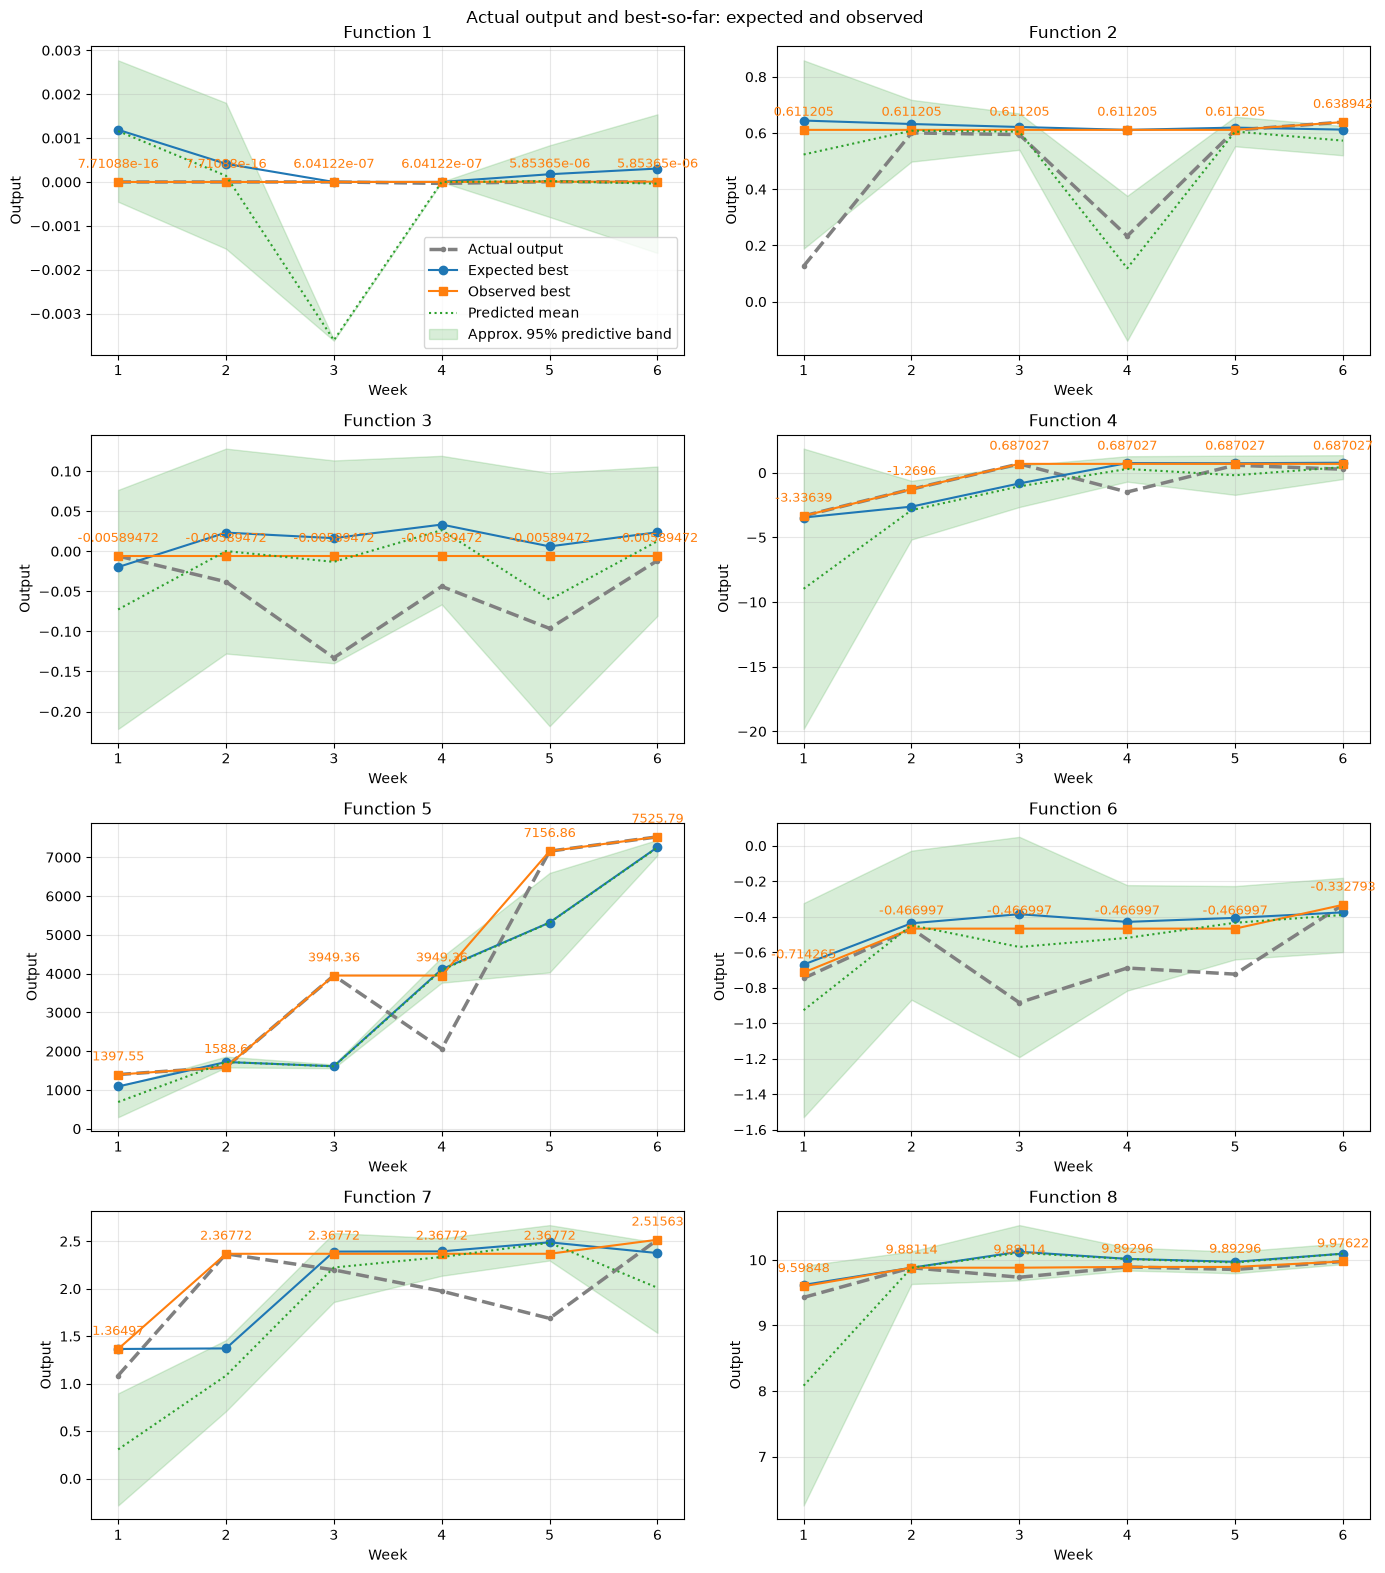

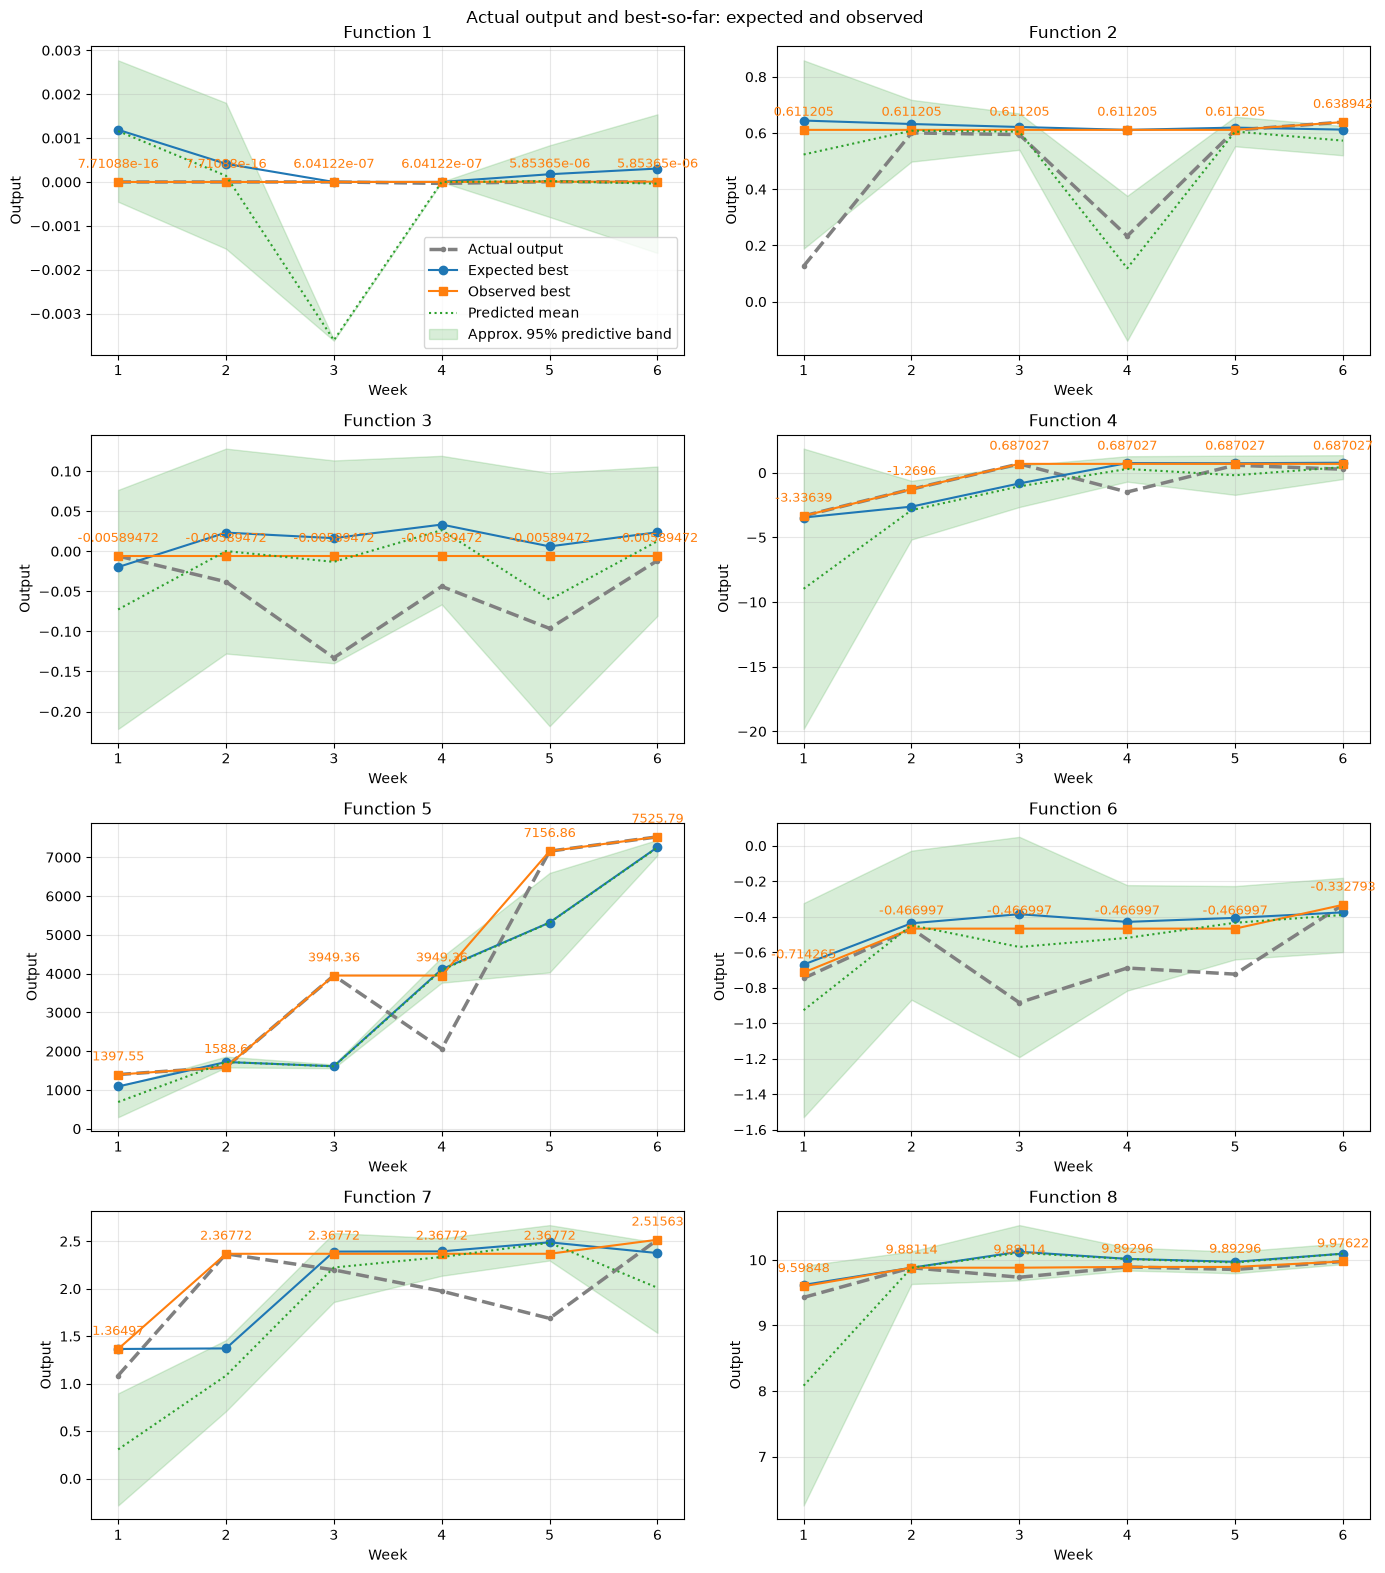

In [15]:
def history_matrix(column):
    return history.records.pivot(index='function_id', columns='week', values=column).reindex(
        index=FUNCTION_IDS, columns=WEEKS,
    ).to_numpy()

actual_outputs = history_matrix('observed_output')
expected_outputs = history_matrix('expected_mean')
stds = history_matrix('expected_std')
expected_best = history_matrix('expected_best')
observed_best = history_matrix('observed_best')
if any(not np.all(np.isfinite(values)) for values in (actual_outputs, expected_outputs, stds, expected_best, observed_best)):
    raise ValueError(f'Week 1-{CURRENT_WEEK} history values must be finite.')
residuals = history.records.groupby('function_id').residual.apply(list).to_dict()

progress_figure, progress_axes = plot_optimum_progress(
    WEEKS, FUNCTION_IDS, actual_outputs, expected_best, observed_best,
    expected_outputs=expected_outputs, stds=stds,
)
display(progress_figure)

## 3. Predictive calibration

The residual plot summarizes saved predictive uncertainty across all evaluated suggestions through `CURRENT_WEEK`. A small sample and function-specific output scales limit what can be inferred; use the plots as diagnostics, not a guarantee of future coverage.

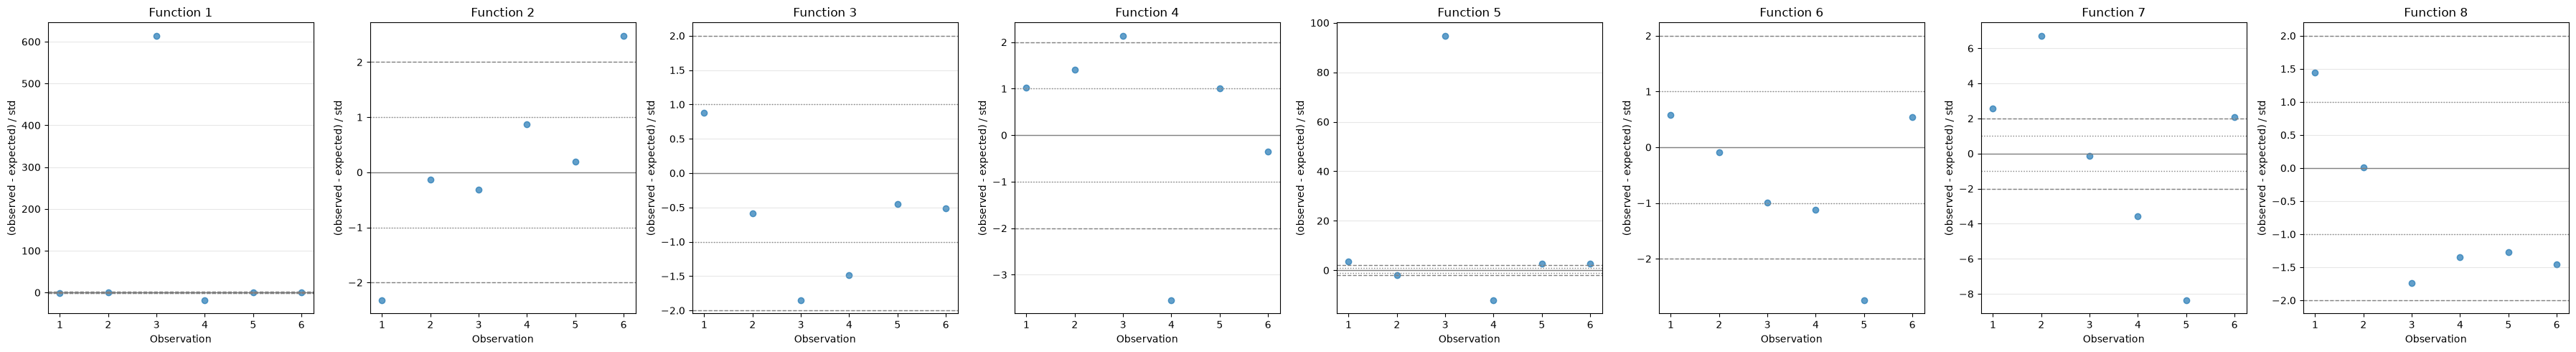

In [16]:
calibration_figure, calibration_ax = plot_calibration(residuals)
display(calibration_figure)
plt.close(progress_figure)
plt.close(calibration_figure)

## 4. Weeks 1-6 per-function strategy summary

Here is the consolidated per-function summary across **Weeks 1–6** (with **Week 1 UCB** kept distinct from **Weeks 2–6 EI**):

| Fn (Dim) | Progress (W0 → W6 Best) | Winning Weeks | What Produced Improvements | What Failed / Stalled | Length-Scale & Rolling Backtest Note |
| :-: | --- | :---: | --- | --- | --- |
| **F1** (2D) | `7.71e-16` → `5.85e-06` *(W5)* | **W3, W5** (`2/6`) | **Local heuristics** near `[0.55–0.56, 0.6815]` | W1 UCB; EI pool in W2 (Matérn 3/2, $\alpha=0.1$) & W6 (RQ, $\alpha=0.1$); W4 heuristic (`x1=0.65`) | ARD Matérn 3/2 flipped its `31.6` cap between `x0` and `x1`; RQ (`l=0.038`) has `6/6` coverage, but `std(y)`-scaled $\xi$ is dominated by the `-3.6e-3` outlier. |
| **F2** (2D) | `0.6112` → `0.6389` *(W6)* | **W6** (`1/6`) | **Local heuristic** (`x0 + 0.01` at `x1=0.9266`) | W1 UCB; W2 EI (Matérn 3/2, $\alpha=0.1$); W3–W5 heuristics (`x1=0.5`, `x0=0.5`, `x0-0.01`) | ARD Matérn 3/2 & RBF both pinned `x1=31.6` every week and underpredicted W6 (`~0.573` vs `0.639`); Matérn 3/2 (`6/6`) now edges RBF (`5/6`) on rolling NLL. |
| **F3** (3D) | `-0.0348` → `-0.0059` *(W1)* | **W1** (`1/6`) *(W6 rank 2)* | **W1 UCB** ($\kappa=1.96$, fixed RBF `l=0.1`); in EI era, **W6 RQ ($\alpha=0.2$)** came closest (`-0.0115`) | W2–W5 ARD Matérn 3/2 EI ($\alpha=0.1$ in W2–W4; $\alpha=0.3$ in W5) | ARD Matérn 3/2 pinned **both `x0, x1 = 31.6`** in W2, W3, W5; isotropic RQ (`l=0.22`, no caps) leads rolling RMSE, NLL, and `6/6` coverage. |
| **F4** (4D) | `-4.0255` → `+0.6870` *(W3)* | **W1, W2, W3** (`3/6`) | **W1 UCB**; **ARD Matérn 3/2 + EI $\alpha=0.1$** (W2, W3) | Lowering EI $\alpha$ under Matérn 3/2 to `0.025` (W4, W5) and `0.0` (W6) | Never hit cap `10` (`l ≈ 3.0–4.2` across all 4 axes); Matérn 3/2 still leads rolling NLL (`2.32`) and predicted W6 cleanly (`z=-0.35`). |
| **F5** (4D) | `1088.86` → `7525.79` *(W6)* | **W1, W2, W3, W5, W6** (`5/6`) | **W1 UCB**; **EI $\alpha=0.1$** every winning EI week — Matérn 3/2 (W2, W3) then **isotropic RQ** (W5, W6) | W4 only (ARD Matérn 3/2, $\alpha=0.1$): crashed `3949 → 2060` (`z=-12.1`) | ARD Matérn 3/2 pinned `x0=100` (W2–W4) and blew `x3` to `32` in W4; isotropic RQ (`l=1.1–1.5`, no caps) leads rolling RMSE/NLL but still underpredicts the corner slope (`z≈+2.7`). |
| **F6** (5D) | `-0.7143` → `-0.3328` *(W6)* | **W2, W6** (`2/6`) | **EI $\alpha=0.1$** in both wins — W2 Matérn 3/2 (`-0.467`), W6 **isotropic RQ** (`-0.333`) | W1 UCB; W3 Matérn 3/2 ($\alpha=0.2$); low/zero $\alpha$ under Matérn 3/2 (W4 `0.05`, W5 `0.0`, `z=-2.75`) | ARD Matérn 3/2 abruptly pinned `x0=31.6` in W5; isotropic RQ (`l=1.1`, no caps) wins rolling RMSE, NLL, and `6/6` coverage. |
| **F7** (6D) | `1.3650` → `2.5156` *(W6)* | **W2, W6** (`2/6`) | **ARD Matérn 3/2 + EI $\alpha=0.1$** produced both wins | W1 UCB; W3 ($\alpha=0.2$); W4 ($\alpha=0.1$); W5 ($\alpha=0.0$, `z=-8.37`) | Both wins had `x2=31.6` capped; W5 dropped `x2` to `2.9` and crashed. Rolling backtest is split: Matérn 3/2–5/2 lead RMSE, while **RQ** cuts NLL in half (`4.87` vs `10.20`). |
| **F8** (8D) | `9.5985` → `9.9762` *(W6)* | **W2, W4, W6** (`3/6`) | **ARD Matérn 3/2 + EI $\alpha=0.1$** (W2, W4); **isotropic RQ + EI $\alpha=0.0$** (W6) | W1 UCB; W3 Matérn 3/2 ($\alpha=0.2$); W5 Matérn 3/2 ($\alpha=0.0$) | ARD Matérn 3/2 pinned `x7=100` in W2–W5; isotropic RQ (`l=7.7`, no caps) leads rolling RMSE, NLL, and `6/6` coverage (mild overprediction near `10.0`). |

### Key patterns and caveats (Weeks 2-6 EI era)

- **Acquisition settings (Weeks 2-6 EI pool, `n = 33`):** $\alpha = 0.1$ coincided with `12/20` (60.0%) incumbent improvements (`7/12` in Weeks 3-6), compared with `1/5` at $\alpha = 0.0$ (only F8 Week 6 under RQ), `0/3` at $\alpha \in \{0.025, 0.05\}$, and `0/5` at $\alpha \in \{0.2, 0.3\}$. Week 1 was the only round using UCB ($\kappa = 1.96$, fixed isotropic RBF `l = 0.1`, `3/8` improved).
- **Kernel and length-scale behavior:** Isotropic Rational Quadratic achieved `4/6` (66.7%) EI-pool improvements with `0/6` upper-cap hits (plus rank 2/21 on F3), whereas ARD Matérn 3/2 hit at least one upper length cap in `17/27` EI-pool fits (`9/27` improved overall; `4/19` in Weeks 3-6). Sudden ARD axis pinning coincided with major misses on F5 (W4) and F6 (W5) and repeated axis blindness on F1-F3.
- **Local heuristics on F1 and F2:** Controlled coordinate-wise overrides produced `3/7` improvements (100% of all gains on F1 and F2), compared with `0/3` for EI pool and `0/2` for Week 1 UCB on those two functions.
- **Methodological caveat:** With one new observation per function per week and multiple settings changing across rounds (new data, kernel, $\alpha$, and heuristic overrides), these associations are descriptive diagnostics to inform Week 7 modeling — not controlled causal proofs or universal optimization rules.